In [1]:
import torch
import torchvision

import numpy as np
import matplotlib.pyplot as plt

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [3]:
import os
from google.colab import userdata

# 토큰 가져오기
try:
    kaggle_token = userdata.get('KAGGLE_TOKEN')
except Exception as e:
    print("코랩 시크릿에 KAGGLE_TOKEN이 설정되지 않았거나 접근 권한이 없습니다.")
    raise e

# 인증 토큰 파일 생성 및 권한 설정
!mkdir -p ~/.kaggle

# 가져온 토큰 변수를 사용해 access_token 파일 생성
with open('/root/.kaggle/access_token', 'w') as f:
    f.write(kaggle_token)

!chmod 600 ~/.kaggle/access_token

# 캐글 라이브러리 설치 및 다운로드
!pip install -q kaggle

os.makedirs('/root/work/data_augmentation/data', exist_ok=True)
%cd /root/work/data_augmentation/data

!kaggle datasets download -d jessicali9530/stanford-dogs-dataset
!unzip -q stanford-dogs-dataset.zip

/root/work/data_augmentation/data
Dataset URL: https://www.kaggle.com/datasets/jessicali9530/stanford-dogs-dataset
License(s): other
100% 750M/750M [00:20<00:00, 39.3MB/s]



## 데이터셋

Oxford-IIIT Pet 이미지와 XML 주석을 사용해 CAM 및 Grad-CAM을 시각화합니다.

In [4]:
import os

dataset_dir = os.path.expanduser("~/work/data_augmentation/data/images/Images/")

# 견종 목록 가져오기
breed_folders = sorted([
    f for f in os.listdir(dataset_dir)
    if os.path.isdir(os.path.join(dataset_dir, f))
])

breed_counts = {}

for breed in breed_folders:
    breed_path = os.path.join(dataset_dir, breed)

    # 폴더 안의 이미지 파일 개수 세기
    images = [
        f for f in os.listdir(breed_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    breed_counts[breed] = len(images)

# 전체 데이터 수 계산
total_images = sum(breed_counts.values())

print(f"총 클래스(견종) 수: {len(breed_counts)}개")
print(f"전체 이미지 수: {total_images}장\n")

print("견종별 이미지 개수:")
for breed, count in breed_counts.items():
    print(f"- {breed}: {count}장")

# 가장 데이터가 많고 적은 견종 확인
if breed_counts:
    most_common = max(breed_counts.items(), key=lambda x: x[1])
    least_common = min(breed_counts.items(), key=lambda x: x[1])

    print(f"\n가장 많은 데이터를 가진 견종: {most_common[0]} ({most_common[1]}장)")
    print(f"가장 적은 데이터를 가진 견종: {least_common[0]} ({least_common[1]}장)")

총 클래스(견종) 수: 120개
전체 이미지 수: 20580장

견종별 이미지 개수:
- n02085620-Chihuahua: 152장
- n02085782-Japanese_spaniel: 185장
- n02085936-Maltese_dog: 252장
- n02086079-Pekinese: 149장
- n02086240-Shih-Tzu: 214장
- n02086646-Blenheim_spaniel: 188장
- n02086910-papillon: 196장
- n02087046-toy_terrier: 172장
- n02087394-Rhodesian_ridgeback: 172장
- n02088094-Afghan_hound: 239장
- n02088238-basset: 175장
- n02088364-beagle: 195장
- n02088466-bloodhound: 187장
- n02088632-bluetick: 171장
- n02089078-black-and-tan_coonhound: 159장
- n02089867-Walker_hound: 153장
- n02089973-English_foxhound: 157장
- n02090379-redbone: 148장
- n02090622-borzoi: 151장
- n02090721-Irish_wolfhound: 218장
- n02091032-Italian_greyhound: 182장
- n02091134-whippet: 187장
- n02091244-Ibizan_hound: 188장
- n02091467-Norwegian_elkhound: 196장
- n02091635-otterhound: 151장
- n02091831-Saluki: 200장
- n02092002-Scottish_deerhound: 232장
- n02092339-Weimaraner: 160장
- n02093256-Staffordshire_bullterrier: 155장
- n02093428-American_Staffordshire_terrier: 164장
- 

In [5]:
import os
from sklearn.model_selection import train_test_split
from torchvision.datasets import ImageFolder

dataset_dir = "/root/work/data_augmentation/data/images/Images"

base_dataset = ImageFolder(dataset_dir)

indices = list(range(len(base_dataset)))
labels = base_dataset.targets

train_val_indices, test_indices = train_test_split(
    indices,
    test_size=0.1,
    random_state=42,
    stratify=labels
)

train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=1/9,
    random_state=42,
    stratify=[labels[i] for i in train_val_indices]
)

print("전체 이미지:", len(base_dataset))
print("훈련 이미지:", len(train_indices))
print("검증 이미지:", len(val_indices))
print("테스트 이미지:", len(test_indices))

전체 이미지: 20580
훈련 이미지: 16464
검증 이미지: 2058
테스트 이미지: 2058


In [6]:
import os
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import ImageFolder

dataset_dir = "/root/work/data_augmentation/data/images/Images"

# 이미지 전처리
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# 전체 이미지 데이터셋 구성
full_dataset = ImageFolder(root=dataset_dir, transform=transform)

# 앞서 만든 인덱스로 데이터 분할
train_dataset = Subset(full_dataset, train_indices)
valid_dataset = Subset(full_dataset, val_indices)
test_dataset = Subset(full_dataset, test_indices)

# 데이터 로더 생성
batch_size = 12

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

num_classes = len(full_dataset.classes)

print(f"Number of classes: {num_classes}")
print(f"Train samples: {len(train_dataset)}")
print(f"Validation samples: {len(valid_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Number of classes: 120
Train samples: 16464
Validation samples: 2058
Test samples: 2058


Label index: 97
Class name: n02109961-Eskimo_dog


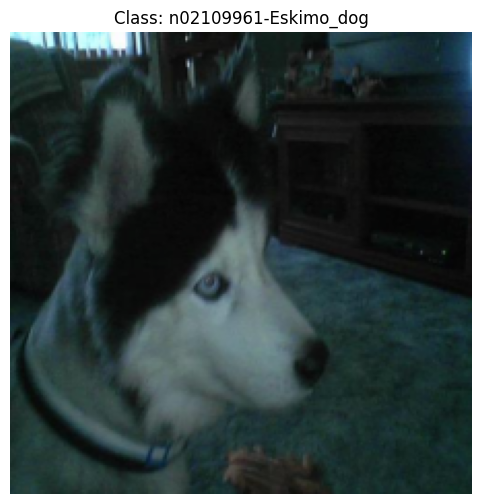

In [8]:
import matplotlib.pyplot as plt
import numpy as np

def visualize(sample):
    img_tensor, label = sample

    # 원본 데이터셋에서 클래스 정보 불러오기
    class_name = full_dataset.classes[label]

    print("Label index:", label)
    print("Class name:", class_name)

    # 정규화 역변환
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    img_np = img_tensor.permute(1, 2, 0).numpy()
    img_np = std * img_np + mean
    img_np = np.clip(img_np, 0, 1)

    # 이미지 출력
    plt.figure(figsize=(6, 6))
    plt.imshow(img_np)

    plt.title(f"Class: {class_name}")
    plt.axis('off')

    plt.show()


# 첫 번째 훈련 샘플 확인
train_sample = train_dataset[0]
visualize(train_sample)

### XML 주석 정보

이미지 파일명, 클래스, 크기, 객체 위치 등의 정보를 담고 있습니다.

In [9]:
import os
import xml.etree.ElementTree as ET

annotation_path = (
    '/root/work/data_augmentation/data/annotations/Annotation/'
    'n02085620-Chihuahua/n02085620_10074'
)

# XML 주석 파일 파싱
tree = ET.parse(annotation_path)
root = tree.getroot()

for elem in root.iter():
    print(f"{elem.tag}: {elem.text}")

annotation: 
	
folder: 02085620
filename: n02085620_10074
source: 
		
database: ImageNet database
size: 
		
width: 333
height: 500
depth: 3
segment: 0
object: 
		
name: Chihuahua
pose: Unspecified
truncated: 0
difficult: 0
bndbox: 
			
xmin: 25
ymin: 10
xmax: 276
ymax: 498


In [10]:
import torch
import torch.nn as nn
from torchvision import models

# ImageNet으로 사전 학습된 ResNet50 불러오기
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

# 마지막 분류층 수정 (120개 견종을 분류하도록 변경)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, len(full_dataset.classes))

model = model.to(device)

model

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 197MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [11]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

In [13]:
def train_model(model, train_loader, valid_loader, criterion, optimizer, num_epochs=2):
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        print(f"\nEpoch {epoch+1}/{num_epochs} 시작")

        for batch_idx, 	(images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()
            if (batch_idx + 1) % 50 == 0:
                print(f"  Step {batch_idx+1} - Loss: {loss.item():.4f}")

        train_loss = running_loss / (batch_idx + 1)
        train_acc = correct / total
        print(f"Train - Loss: {train_loss:.4f}, Accuracy: {train_acc*100:.2f}%")

        # 검증 단계
        model.eval()
        running_loss = 0.0
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in valid_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                running_loss += loss.item()
                _, preds = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (preds == labels).sum().item()
        valid_loss = running_loss / len(valid_loader)
        valid_acc = correct / total
        print(f"Validation - Loss: {valid_loss:.4f}, Accuracy: {valid_acc*100:.2f}%")

In [14]:
%%time

train_model(model, train_loader, valid_loader, criterion, optimizer, num_epochs=2)


Epoch 1/2 시작
  Step 50 - Loss: 3.6519
  Step 100 - Loss: 3.6350
  Step 150 - Loss: 3.7904
  Step 200 - Loss: 4.2826
  Step 250 - Loss: 4.3081
  Step 300 - Loss: 2.7361
  Step 350 - Loss: 2.8490
  Step 400 - Loss: 3.1458
  Step 450 - Loss: 3.6690
  Step 500 - Loss: 3.2425
  Step 550 - Loss: 3.2354
  Step 600 - Loss: 3.2915
  Step 650 - Loss: 2.5948
  Step 700 - Loss: 3.2190
  Step 750 - Loss: 2.3467
  Step 800 - Loss: 4.0414
  Step 850 - Loss: 2.8308
  Step 900 - Loss: 4.0682
  Step 950 - Loss: 2.3064
  Step 1000 - Loss: 3.4912
  Step 1050 - Loss: 2.7196
  Step 1100 - Loss: 2.1881
  Step 1150 - Loss: 2.5485
  Step 1200 - Loss: 2.3127
  Step 1250 - Loss: 2.1326
  Step 1300 - Loss: 2.6567
  Step 1350 - Loss: 2.8356
Train - Loss: 3.0143, Accuracy: 25.69%
Validation - Loss: 2.7425, Accuracy: 31.15%

Epoch 2/2 시작
  Step 50 - Loss: 1.9138
  Step 100 - Loss: 2.9236
  Step 150 - Loss: 2.4540
  Step 200 - Loss: 2.0938
  Step 250 - Loss: 3.4862
  Step 300 - Loss: 1.7170
  Step 350 - Loss: 2.3000

In [15]:
cam_model_path = '/content/cam_model.pt'

torch.save(model, cam_model_path)

In [16]:
def unnormalize(img_tensor):
    """
    img_tensor: [C, H, W] 텐서 (전처리 적용됨)
    ImageNet 평균 및 표준편차를 이용하여 복원 (RGB 순서)
    """
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img = img_tensor.cpu().numpy().transpose(1, 2, 0)
    img = std * img + mean
    img = np.clip(img, 0, 1)
    img = np.uint8(255 * img)
    return img

In [17]:
image, label = train_dataset[0]
sample_image = image.unsqueeze(0).to(device)

In [18]:
model = torch.load(cam_model_path, weights_only=False)

In [21]:
def generate_cam(model, image):
    model.eval()
    features = []

    # 마지막 합성곱 레이어의 출력값 저장
    def hook(module, input, output):
        features.append(output.detach())

    hook_handle = model.layer4.register_forward_hook(hook)

    try:
        with torch.no_grad():
            output = model(image)
    finally:
        hook_handle.remove()

    # 예측된 클래스 선택
    pred_class = output.argmax(dim=1).item()

    # 특징 맵 추출
    fmap = features[0][0]

    # 완전연결층 가중치 추출
    fc_weights = model.fc.weight[pred_class]

    # CAM 생성
    cam = torch.zeros(
        fmap.shape[1:],
        dtype=torch.float32,
        device=image.device
    )

    for i, w in enumerate(fc_weights):
        cam += w * fmap[i]

    # CAM 정규화
    cam = cam.detach().cpu().numpy()
    cam = np.maximum(cam, 0)

    cam_min = np.min(cam)
    cam_max = np.max(cam)

    cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)

    return cam

In [22]:
cam = generate_cam(model, sample_image)

In [23]:
def visualize_cam(cam):
    plt.imshow(cam, cmap='jet')
    plt.colorbar()
    plt.title("CAM")
    plt.axis('off')
    plt.show()

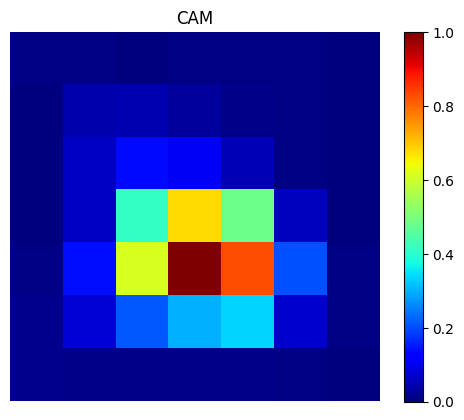

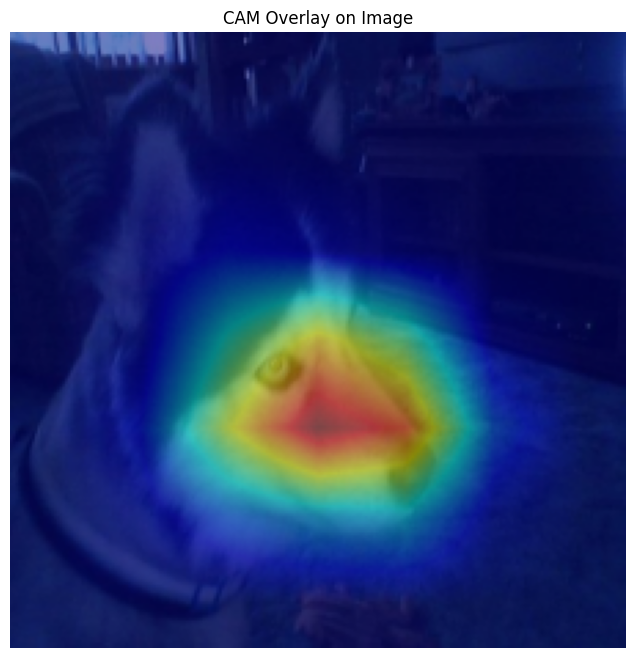

In [24]:
import cv2

def visualize_cam_on_image(cam, img, alpha=0.5):
    # CAM을 원본 이미지 크기로 조정
    cam_resized = cv2.resize(cam, (img.shape[1], img.shape[0]))

    # CAM을 컬러 히트맵으로 변환 (cv2.applyColorMap은 BGR을 반환하므로 RGB로 변환)
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    # 원본 이미지와 히트맵을 alpha blending으로 합성
    overlay = heatmap * alpha + img * (1 - alpha)
    overlay = overlay.astype(np.uint8)

    plt.figure(figsize=(8,8))
    plt.imshow(overlay)
    plt.title("CAM Overlay on Image")
    plt.axis('off')
    plt.show()


# 원본 이미지 복원
orig_img = unnormalize(image)

# CAM 단독 시각화
visualize_cam(cam)

# 원본 이미지 위에 CAM을 겹쳐 시각화
visualize_cam_on_image(cam, orig_img)

In [25]:
def generate_grad_cam(model, image, target_layer_name):
    model.eval()
    features = {}
    gradients = {}

    # 순전파 후크: 대상 레이어의 출력을 저장
    def forward_hook(module, input, output):
        features['value'] = output.detach()

    # 역전파 후크: 대상 레이어의 기울기를 저장 (전체 역전파 후크 사용)
    def backward_hook(module, grad_in, grad_out):
        gradients['value'] = grad_out[0].detach()

    # 모델에서 target_layer_name과 이름이 일치하는 레이어 검색
    target_layer = dict(model.named_modules()).get(target_layer_name, None)
    if target_layer is None:
        raise ValueError(f"Layer '{target_layer_name}' not found in the model.")

    # 후크 등록
    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_full_backward_hook(backward_hook)

    # 순전파 실행
    output = model(image)
    pred_class = output.argmax(dim=1).item()

    # 예측 클래스에 대해 역전파 수행
    model.zero_grad()
    score = output[0, pred_class]
    score.backward()

    # 후크 제거
    forward_handle.remove()
    backward_handle.remove()

    # 저장된 특징 맵과 기울기 추출 (크기: [C, H, W])
    fmap = features['value'][0]
    grads = gradients['value'][0]

    # 각 채널의 기울기에 전역 평균 풀링을 적용해 가중치 계산
    weights = torch.mean(grads, dim=(1, 2))

    # 가중합: 각 채널의 특징 맵에 가중치를 곱해 합산
    grad_cam = torch.zeros(fmap.shape[1:], dtype=torch.float32, device=fmap.device)
    for i, w in enumerate(weights):
        grad_cam += w * fmap[i, :, :]
    grad_cam = grad_cam.cpu().numpy()

    # ReLU와 정규화 적용: 음수 값을 제거하고 [0, 1] 범위로 변환
    grad_cam = np.maximum(grad_cam, 0)
    grad_cam = (grad_cam - grad_cam.min()) / (grad_cam.max() - grad_cam.min() + 1e-8)

    return grad_cam

===== layer1 =====


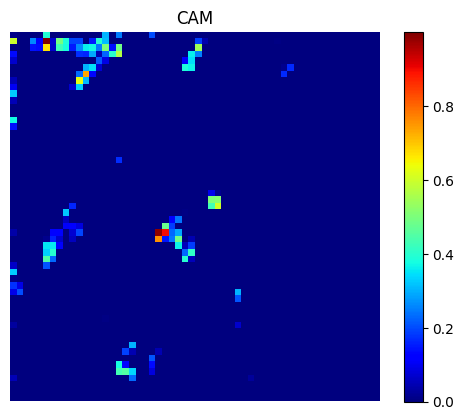

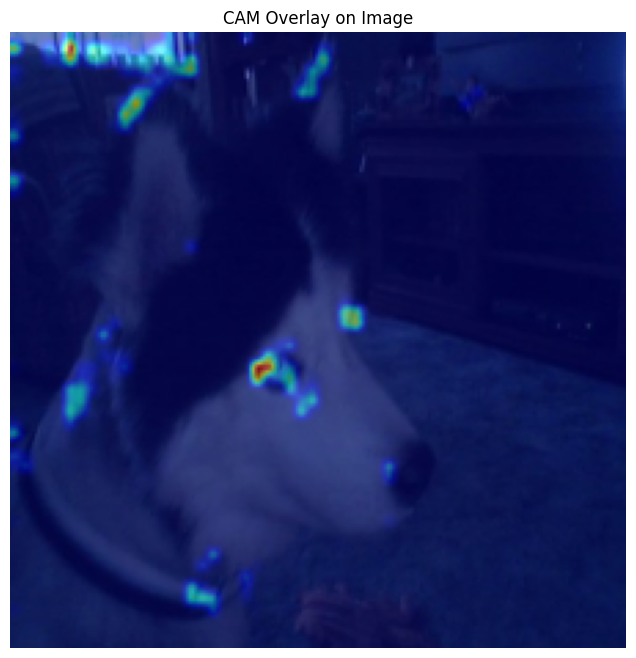

===== layer2 =====


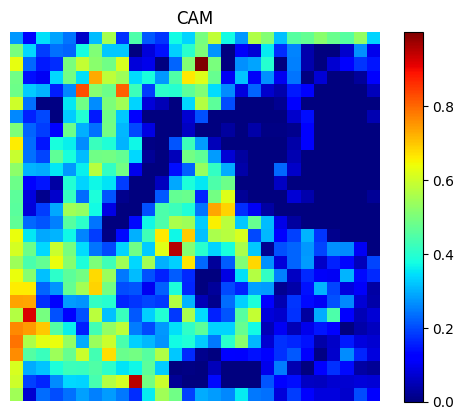

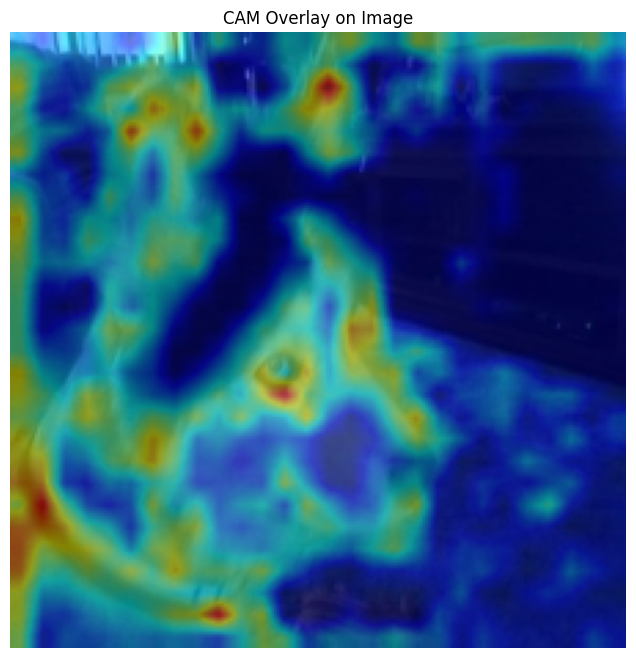

===== layer3 =====


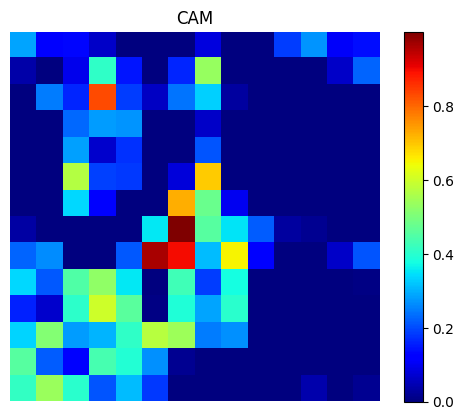

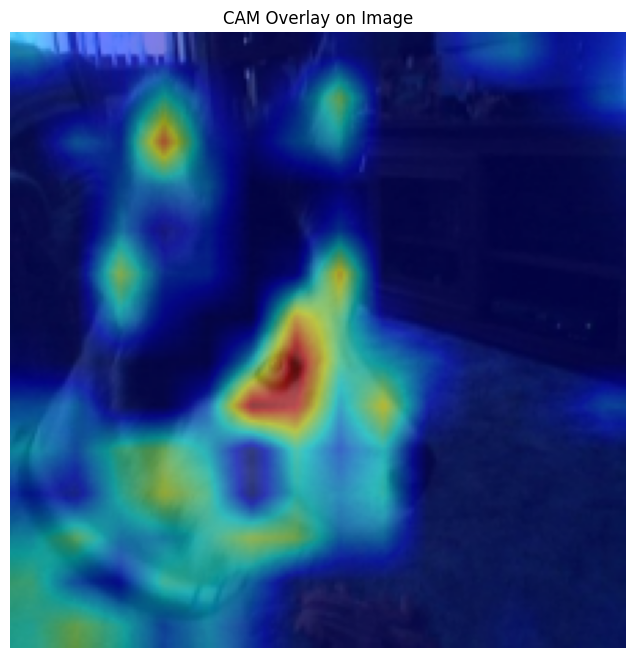

===== layer4 =====


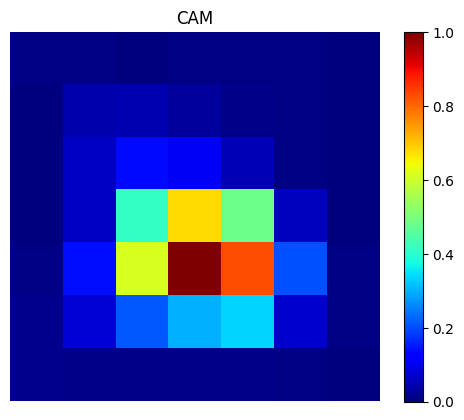

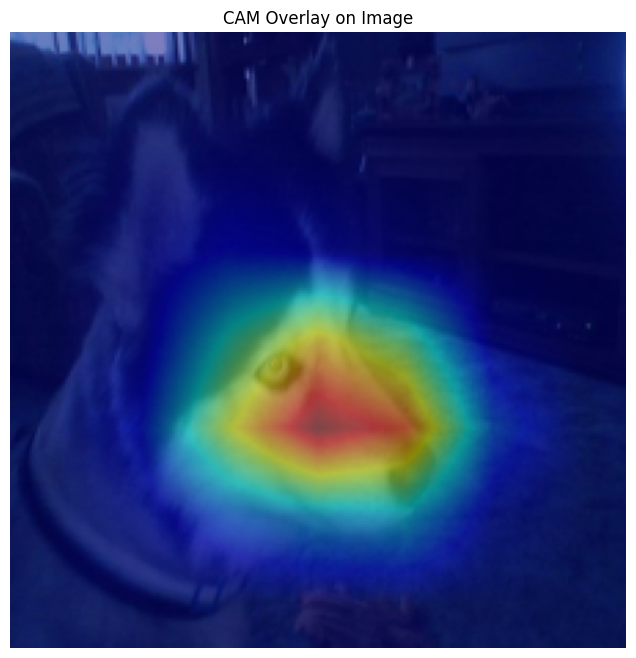

In [26]:
# 관찰할 레이어
target_layers = ["layer1", "layer2", "layer3", "layer4"]

# 전처리된 이미지를 원본 이미지로 복원
orig_img = unnormalize(image)

# 각 레이어의 Grad-CAM 생성 및 시각화
for layer_name in target_layers:

    print(f"===== {layer_name} =====")

    # Grad-CAM 생성
    grad_cam = generate_grad_cam(model, sample_image, target_layer_name=layer_name)

    # Grad-CAM 단독 시각화
    visualize_cam(grad_cam)

    # 원본 이미지와 Grad-CAM을 겹쳐 시각화
    visualize_cam_on_image(grad_cam, orig_img)